# Freight rate - exploration

In [70]:
import pandas as pd
import numpy as np
train = pd.read_csv("../data/train-test.csv")
val = pd.read_csv("../data/validation.csv")

print(train.shape, val.shape)
print(train.head())
print(train.describe())
print(train.isna().sum())
print("Train dates:", train["date"].min(), "to", train["date"].max())
print("Val dates:", val["date"].min(), "to", val["date"].max())

(48000, 14) (12000, 13)
     load_id        pickup      delivery  pickup_lat  pickup_lon  \
0  TR-000001      Richmond     Baltimore    38.09122   -76.78906   
1  TR-000002      Richmond  Philadelphia    38.09122   -76.78906   
2  TR-000003  Philadelphia     Green Bay    39.22317   -72.96710   
3  TR-000004      Hartford       Atlanta    39.55328   -72.18051   
4  TR-000005        Dallas     Nashville    31.83025   -94.38343   

   delivery_lat  delivery_lon  distance equipment   weight        date  \
0      38.16908     -72.74564     274.3   Dry Van  30658.0  2025-01-01   
1      39.22317     -72.96710     280.5    Reefer  17555.0  2025-01-01   
2      44.30296     -87.52871     967.8   Dry Van  31721.0  2025-01-01   
3      34.84933     -86.28940     965.4   Dry Van  32333.0  2025-01-01   
4      35.29479     -88.08915     541.9    Reefer  35183.0  2025-01-01   

   market_index  quote_signal  posted_rate  
0       0.95684       2.39595       645.41  
1       0.97623       2.43355   

train = jan-oct, val = nov-dec so we're predicting the future. missing: weight 300, market_index 374

### negative weights

In [71]:
#let's check if there are any negative weights
print((train["weight"] <= 0).sum())

292


292 negative weights, min = -max (47500) so probably a sign typo -> abs()

### price per mile

count    48000.000000
mean         2.215347
std          0.583887
min          0.333709
25%          1.986974
50%          2.145348
75%          2.342696
max         14.125294
Name: rpm, dtype: float64
0.001     0.437364
0.010     1.673521
0.990     3.176940
0.999    10.068775
Name: rpm, dtype: float64


<Axes: >

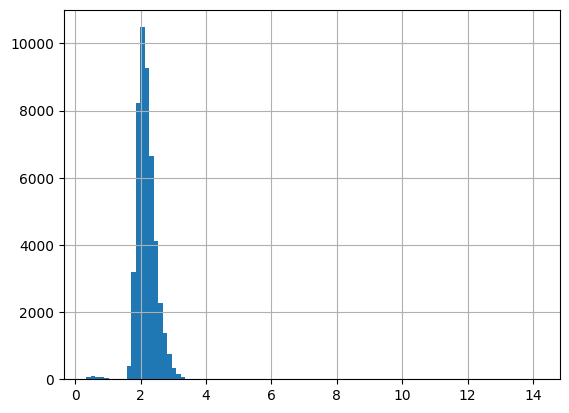

In [72]:
train["rpm"] = train["posted_rate"] / train["distance"]
print(train["rpm"].describe())
print(train["rpm"].quantile([0.001, 0.01, 0.99, 0.999]))
train["rpm"].hist(bins=100)

most loads 1.7-3.2 $/mile but some at 0.3 and some up to 14, need to check per lane

### outliers vs lane median

In [73]:
lane_median = train.groupby(["pickup", "delivery", "equipment"])["rpm"].transform("median")
train["ratio"] = train["rpm"] / lane_median

print(train["ratio"].quantile([0.001, 0.005, 0.01, 0.5, 0.99, 0.995, 0.999]))
print("Too expensive (>2x):", (train["ratio"] > 2).sum())
print("Too cheap (<0.5x):", (train["ratio"] < 0.5).sum())
print(train[train["ratio"] > 2][["pickup", "delivery", "distance", "posted_rate", "ratio"]].head(10))
print(train[train["ratio"] < 0.5][["pickup", "delivery", "distance", "posted_rate", "ratio"]].head(10))

0.001    0.204871
0.005    0.358058
0.010    0.888118
0.500    1.000000
0.990    1.118955
0.995    2.701552
0.999    4.478954
Name: ratio, dtype: float64
Too expensive (>2x): 303
Too cheap (<0.5x): 325
           pickup      delivery  distance  posted_rate     ratio
469       Phoenix  Jacksonville    2154.3     10854.69  2.622431
785   Kansas City    Charleston     861.5      4587.83  2.521870
870         Tulsa   Baton Rouge     305.6      4069.24  4.677205
1149      Houston   Baton Rouge     170.3      1359.60  2.627363
1175       Tucson       Phoenix     260.5      1609.22  2.591974
1329   Harrisburg         Tulsa    1190.5      7100.73  2.846447
1417       Dallas       Atlanta     613.6      4485.75  3.023827
1466  Los Angeles      Syracuse    2786.0     24140.21  4.394789
1746     Columbia       Houston     882.9      6394.62  3.172840
1949     Hartford          Reno    2794.2     13918.00  2.462160
           pickup       delivery  distance  posted_rate     ratio
50    Los Angeles

99% of loads within ~12% of their lane median. ~630 rows (1.3%) are 2-5x off

In [74]:
train["group"] = np.where(train["ratio"] > 2, "too_high",
                 np.where(train["ratio"] < 0.5, "too_low", "normal"))

# 1. By month: are errors concentrated in one period?
print(pd.crosstab(train["date"].str[:7], train["group"]))

# 2. By truck type: same share as normal loads?
print(pd.crosstab(train["equipment"], train["group"], normalize="columns").round(3))

# 3. Do the bad rows differ in anything else?
print(train.groupby("group")[["distance", "weight", "market_index", "quote_signal"]].median())

# 4. How far off are they?
print(train[train["group"] == "too_high"]["ratio"].describe())
print(train[train["group"] == "too_low"]["ratio"].describe())

group    normal  too_high  too_low
date                              
2025-01    4844        36       38
2025-02    4283        28       26
2025-03    4971        29       36
2025-04    4759        26       34
2025-05    4861        18       34
2025-06    4720        38       25
2025-07    4851        32       29
2025-08    4694        31       34
2025-09    4609        31       30
2025-10    4780        34       39
group      normal  too_high  too_low
equipment                           
Dry Van     0.567     0.640    0.520
Flatbed     0.183     0.135    0.185
Reefer      0.251     0.224    0.295
          distance   weight  market_index  quote_signal
group                                                  
normal      953.85  31446.0       1.05587      2.055855
too_high    947.00  31284.0       1.04805      2.034740
too_low     848.90  29265.5       1.05092      2.047170
count    303.000000
mean       3.484493
std        0.816062
min        2.077253
25%        2.842444
50%        3.34

outliers spread evenly over months / equipment / distance / weight / market_index, nothing explains them -> random entry errors. drop from train only

In [75]:
train["day"] = pd.to_datetime(train["date"]).dt.day_name()
order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

# 1. Outliers per weekday
print(pd.crosstab(train["day"], train["group"]).reindex(order))

# 2. Normal price per weekday (normal loads only, compared with their lane)
normal = train[train["group"] == "normal"]
print(normal.groupby("day")["ratio"].mean().reindex(order).round(3))
print(normal.groupby("day").size().reindex(order))

group      normal  too_high  too_low
day                                 
Monday       6680        39       50
Tuesday      6643        49       45
Wednesday    6907        56       44
Thursday     6833        52       49
Friday       6889        31       55
Saturday     6696        33       41
Sunday       6724        43       41
day
Monday       0.994
Tuesday      0.999
Wednesday    1.006
Thursday     1.009
Friday       1.005
Saturday     0.998
Sunday       0.992
Name: ratio, dtype: float64
day
Monday       6680
Tuesday      6643
Wednesday    6907
Thursday     6833
Friday       6889
Saturday     6696
Sunday       6724
dtype: int64


same for weekdays. small weekly effect though: wed/thu ~+1%, sun/mon ~-0.7% -> add day of week

### monthly trend

In [76]:
train["month"] = train["date"].str[:7]
normal = train[train["group"] == "normal"]
print(normal.groupby("month")[["rpm", "ratio", "market_index", "quote_signal"]].mean().round(3))

val["month"] = val["date"].str[:7]
print(val.groupby("month")[["market_index", "quote_signal"]].mean().round(3))

           rpm  ratio  market_index  quote_signal
month                                            
2025-01  2.073  0.961         0.927         2.068
2025-02  2.096  0.971         0.996         2.096
2025-03  2.184  0.997         1.073         2.179
2025-04  2.191  1.001         1.207         1.965
2025-05  2.246  1.019         1.301         1.913
2025-06  2.298  1.036         1.280         2.297
2025-07  2.229  1.014         1.201         1.923
2025-08  2.164  0.992         0.981         2.053
2025-09  2.205  1.004         0.893         2.200
2025-10  2.213  1.007         0.957         1.943
         market_index  quote_signal
month                              
2025-11         0.919         2.055
2025-12         0.935         2.048


prices low in jan, peak in june. market_index has the same shape BUT sep-oct index is low like jan while prices are normal

In [77]:
# average market_index for each day, taken from validation.csv
daily_market = val.groupby("date")["market_index"].mean()
print(daily_market.loc["2025-12-01":"2025-12-31"])

date
2025-12-01    0.834919
2025-12-02    0.914680
2025-12-03    0.994063
2025-12-04    1.024021
2025-12-05    0.975120
2025-12-06    0.889154
2025-12-07    0.830590
2025-12-08    0.840110
2025-12-09    0.917263
2025-12-10    0.998907
2025-12-11    1.027247
2025-12-12    0.981448
2025-12-13    0.896591
2025-12-14    0.838246
2025-12-15    0.847841
2025-12-16    0.924192
2025-12-17    1.002121
2025-12-18    1.033978
2025-12-19    0.988674
2025-12-20    0.901828
2025-12-21    0.844123
2025-12-22    0.859907
2025-12-23    0.930366
2025-12-24    1.014732
2025-12-25    1.044547
2025-12-26    0.997196
2025-12-27    0.914528
2025-12-28    0.858023
2025-12-29    0.869552
2025-12-30    0.944019
2025-12-31    1.027251
Name: market_index, dtype: float64


not used in the end. in dec market_index goes in a weekly wave (low mon/sun, high thu)

### market_index missing values

In [78]:
print(train.groupby("date")["market_index"].std().describe())

count    304.000000
mean       0.024939
std        0.001423
min        0.020531
25%        0.024024
50%        0.024850
75%        0.025815
max        0.029482
Name: market_index, dtype: float64


std within a day ~0.025 so fill missing with the daily mean

### cleaning

In [79]:
def clean(df):
    df = df.copy()
    # 1. negative weights are sign typos
    df["weight"] = df["weight"].abs()
    # 2. missing weight -> median weight of that truck type
    df["weight"] = df["weight"].fillna(df.groupby("equipment")["weight"].transform("median"))
    # 3. missing market_index -> average of that day
    df["market_index"] = df["market_index"].fillna(df.groupby("date")["market_index"].transform("mean"))
    return df

train_clean = clean(train)
val_clean = clean(val)

# 4. remove the bad prices (training only!)
train_clean = train_clean[(train_clean["ratio"] >= 0.5) & (train_clean["ratio"] <= 2)]

print(train_clean.shape, val_clean.shape)
print(train_clean[["weight", "market_index"]].isna().sum())
print(val_clean[["weight", "market_index"]].isna().sum())
print("min weight:", train_clean["weight"].min())

(47372, 19) (12000, 14)
weight          0
market_index    0
dtype: int64
weight          0
market_index    0
dtype: int64
min weight: 5000.0


weight -> abs, fill with equipment median. market_index -> daily mean. drop ratio <0.5 or >2 (train only, val keeps all 12000)

note: lanes with 1-2 loads can't be checked this way

### distance vs straight line

In [80]:
def straight_line_miles(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    a = np.sin((lat2-lat1)/2)**2 + np.cos(lat1)*np.cos(lat2)*np.sin((lon2-lon1)/2)**2
    return 3958.8 * 2 * np.arcsin(np.sqrt(a))

for df in [train_clean, val_clean]:
    df["straight"] = straight_line_miles(df["pickup_lat"], df["pickup_lon"],
                                         df["delivery_lat"], df["delivery_lon"])
    df["dist_ratio"] = df["distance"] / df["straight"]

print(train_clean["dist_ratio"].describe())
print("Train, distance > 2x straight:", (train_clean["dist_ratio"] > 2).sum())
print("Val, distance > 2x straight:", (val_clean["dist_ratio"] > 2).sum())
print(train_clean[train_clean["dist_ratio"] > 2][["pickup", "delivery", "distance", "straight", "rpm"]].head(10))

count    47372.000000
mean         1.194648
std          0.144287
min          1.058090
25%          1.164763
50%          1.182231
75%          1.204762
max          9.634919
Name: dist_ratio, dtype: float64
Train, distance > 2x straight: 22
Val, distance > 2x straight: 16
            pickup     delivery  distance  straight       rpm
1464       Lubbock       Austin      70.0  34.46283  3.365571
1914       Lubbock       Austin      70.0  34.46283  3.210286
4140   New Orleans   Shreveport      70.0   7.26524  2.815143
5091   New Orleans   Shreveport      70.0   7.26524  3.002000
6960   New Orleans   Shreveport      70.0   7.26524  3.193143
8589        Austin      Lubbock      70.0  34.46283  3.010429
9348    Shreveport  New Orleans      70.0   7.26524  3.319000
11311      Lubbock       Austin      70.0  34.46283  3.435143
11327       Austin      Lubbock      78.9  34.46283  3.124715
11949   Shreveport  New Orleans      70.0   7.26524  3.051286


distance ~1.18x straight line, ok. the >2x ones all have distance=70 -> looks like a minimum floor, coords seem approximate (new orleans-shreveport 7 miles??). prices look normal so keep them

### cities in val not in train

In [81]:
train_cities = set(train["pickup"]) | set(train["delivery"])
val_cities = set(val["pickup"]) | set(val["delivery"])
unseen = val_cities - train_cities
print("Cities in validation but never in training:", len(unseen))
print(sorted(unseen))
print("Validation loads touching an unseen city:",
      (val["pickup"].isin(unseen) | val["delivery"].isin(unseen)).sum())

Cities in validation but never in training: 8
['Allentown', 'Charlotte', 'Chicago', 'Jackson', 'Knoxville', 'Laredo', 'Norfolk', 'San Diego']
Validation loads touching an unseen city: 1447


8 cities / 1447 val loads (12%) never seen in train -> use lat/lon instead of city names

(sep-oct test can't check this, all sep-oct cities are in jan-aug)

### split

time split: train jan-aug, test sep-oct. no random split since val is in the future

In [82]:
train_part = train_clean[train_clean["date"] < "2025-09-01"].copy()
test_part = train_clean[train_clean["date"] >= "2025-09-01"].copy()
print(train_part.shape, test_part.shape)
print(train_part["date"].max(), test_part["date"].min())

(37983, 21) (9389, 21)
2025-08-31 2025-09-01


### baseline

In [83]:
#Creating a baseline model that predicts the posted_rate based on the median price per mile (rpm) for each lane and equipment type.
#  If a lane is unseen in the training data, it falls back to the median rpm for that equipment type.
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error

# normal price per mile, learned ONLY from train_part
lane_rpm = train_part.groupby(["pickup", "delivery", "equipment"])["rpm"].median()
equip_rpm = train_part.groupby("equipment")["rpm"].median()

def baseline_predict(df):
    keys = list(zip(df["pickup"], df["delivery"], df["equipment"]))
    rpm = pd.Series(keys, index=df.index).map(lane_rpm)
    rpm = rpm.fillna(df["equipment"].map(equip_rpm))  # unseen routes
    return rpm * df["distance"]

pred = baseline_predict(test_part)
print("MAE  ($):", round(mean_absolute_error(test_part["posted_rate"], pred), 2))
print("MAPE (%):", round(mean_absolute_percentage_error(test_part["posted_rate"], pred) * 100, 2))

MAE  ($): 93.59
MAPE (%): 3.89


baseline 3.89%, model needs to beat that

### lightgbm - feature tests

In [84]:
import lightgbm as lgb

for df in [train_part, test_part]:
    df["dow"] = pd.to_datetime(df["date"]).dt.dayofweek        # 0 = Monday
    df["equip"] = df["equipment"].astype("category")

base = ["distance", "equip", "weight", "pickup_lat", "pickup_lon", "delivery_lat", "delivery_lon"]

experiments = {
    "base only":              base,
    "+ dow":                  base + ["dow"],
    "+ quote_signal":         base + ["quote_signal"],
    "+ market_index":         base + ["market_index"],
    "+ quote_signal + dow":   base + ["quote_signal", "dow"],
    "+ all":                  base + ["quote_signal", "dow", "market_index"],
}

for name, feats in experiments.items():
    model = lgb.LGBMRegressor(n_estimators=800, learning_rate=0.05, num_leaves=63, verbose=-1)
    model.fit(train_part[feats], train_part["rpm"])            # predict price PER MILE
    pred = model.predict(test_part[feats]) * test_part["distance"]  # back to dollars
    print(f"{name:25s} MAPE = {mean_absolute_percentage_error(test_part['posted_rate'], pred)*100:.2f}%")

base only                 MAPE = 2.52%
+ dow                     MAPE = 2.44%
+ quote_signal            MAPE = 2.01%
+ market_index            MAPE = 4.75%
+ quote_signal + dow      MAPE = 2.03%
+ all                     MAPE = 3.71%


quote_signal helps the most. market_index makes it way worse (4.75%) even though it looked useful in EDA - sep-oct index looks like jan but prices aren't jan-cheap, model learns the wrong thing -> dropped. a random split would have hidden this

keeping dow even if it barely changes the error, otherwise the december chart is flat

final: base + quote_signal + dow (2.03%)

Trying out Other Models

In [90]:
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor

X_tr = pd.get_dummies(train_part[final_feats], columns=["equip"])
X_te = pd.get_dummies(test_part[final_feats], columns=["equip"]).reindex(columns=X_tr.columns, fill_value=0)

for name, m in [("Ridge (linear)", Ridge()),
                ("Random forest", RandomForestRegressor(n_estimators=300, n_jobs=-1, random_state=0)),
                ("LightGBM", lgb.LGBMRegressor(objective="l1",n_estimators=800, learning_rate=0.05, num_leaves=63, verbose=-1))]:
    m.fit(X_tr, train_part["rpm"])
    pred = m.predict(X_te) * test_part["distance"]
    print(f"{name:15s} MAPE = {mean_absolute_percentage_error(test_part['posted_rate'], pred)*100:.2f}%")

Ridge (linear)  MAPE = 4.23%
Random forest   MAPE = 1.53%
LightGBM        MAPE = 1.30%


In [ ]:
final_feats = base + ["quote_signal", "dow"]

model = lgb.LGBMRegressor(n_estimators=800, learning_rate=0.05, num_leaves=63, verbose=-1)
model.fit(train_part[final_feats], train_part["rpm"])

raw_test = clean(train)
raw_test = raw_test[raw_test["date"] >= "2025-09-01"].copy()
raw_test["dow"] = pd.to_datetime(raw_test["date"]).dt.dayofweek
raw_test["equip"] = raw_test["equipment"].astype("category")

for name, df in [("clean Sep-Oct", test_part), ("raw Sep-Oct", raw_test)]:
    pred = model.predict(df[final_feats]) * df["distance"]
    err = (df["posted_rate"] - pred).abs() / df["posted_rate"]
    print(f"{name:15s} rows={len(df)}  MAPE={err.mean()*100:.2f}%  median error={err.median()*100:.2f}%")

clean Sep-Oct   rows=9389  MAPE=2.03%  median error=1.36%
raw Sep-Oct     rows=9523  MAPE=4.42%  median error=1.38%


### check on raw sep-oct (with outliers)

In [86]:
final_feats = base + ["quote_signal", "dow"]

model = lgb.LGBMRegressor(n_estimators=800, learning_rate=0.05, num_leaves=63, verbose=-1)
model.fit(train_part[final_feats], train_part["rpm"])

raw_test = clean(train)
raw_test = raw_test[raw_test["date"] >= "2025-09-01"].copy()
raw_test["dow"] = pd.to_datetime(raw_test["date"]).dt.dayofweek
raw_test["equip"] = raw_test["equipment"].astype("category")

for name, df in [("clean Sep-Oct", test_part), ("raw Sep-Oct", raw_test)]:
    pred = model.predict(df[final_feats]) * df["distance"]
    err = (df["posted_rate"] - pred).abs() / df["posted_rate"]
    print(f"{name:15s} rows={len(df)}  MAPE={err.mean()*100:.2f}%  median error={err.median()*100:.2f}%")

clean Sep-Oct   rows=9389  MAPE=2.03%  median error=1.36%
raw Sep-Oct     rows=9523  MAPE=4.42%  median error=1.38%


raw mape is 4.42% but median error is the same (~1.4%) so the gap is just the bad prices

### final model on all jan-oct + val predictions

In [87]:
features = ["distance", "equip", "weight", "pickup_lat", "pickup_lon",
            "delivery_lat", "delivery_lon", "quote_signal", "dow"]

def add_features(df):
    df = df.copy()
    df["dow"] = pd.to_datetime(df["date"]).dt.dayofweek
    df["equip"] = pd.Categorical(df["equipment"], categories=["Dry Van", "Flatbed", "Reefer"])
    return df

full = add_features(train_clean)
valf = add_features(val_clean)

final_model = lgb.LGBMRegressor(n_estimators=800, learning_rate=0.05, num_leaves=63, verbose=-1)
final_model.fit(full[features], full["rpm"])

# 1. validation predictions
val_pred = final_model.predict(valf[features]) * valf["distance"]
template = pd.read_csv("../data/validation-predictions-template.csv")
template["predicted_rate"] = template["load_id"].map(dict(zip(valf["load_id"], val_pred)))
template.to_csv("../validation_predictions.csv", index=False)
print(template.describe(), template["predicted_rate"].isna().sum())

       predicted_rate
count    12000.000000
mean      2357.406686
std       1375.091961
min        180.268476
25%       1268.210347
50%       2025.091783
75%       3363.080758
max       6867.978607 0


no missing, all positive, mean 2357 (train 2374)

### december file

In [88]:
dec = pd.read_csv("../data/december-chart-inputs.csv")
dec.columns = dec.columns.str.strip()
for col in ["pickup", "delivery", "equipment", "date"]:
    dec[col] = dec[col].astype(str).str.strip()
original_cols = list(dec.columns)
print(original_cols)

['pickup', 'delivery', 'distance', 'equipment', 'weight', 'date', 'predicted_rate']


In [89]:
coords = pd.concat([
    train[["pickup", "pickup_lat", "pickup_lon"]].set_axis(["city", "lat", "lon"], axis=1),
    train[["delivery", "delivery_lat", "delivery_lon"]].set_axis(["city", "lat", "lon"], axis=1),
]).groupby("city").first()

decf = dec.copy()
decf["pickup_lat"] = decf["pickup"].map(coords["lat"])
decf["pickup_lon"] = decf["pickup"].map(coords["lon"])
decf["delivery_lat"] = decf["delivery"].map(coords["lat"])
decf["delivery_lon"] = decf["delivery"].map(coords["lon"])

daily_qs = val.groupby("date")["quote_signal"].mean()
decf["quote_signal"] = decf["date"].map(daily_qs)

decf = add_features(decf)
print("missing:", decf[features].isna().sum().sum())

dec["predicted_rate"] = final_model.predict(decf[features]) * decf["distance"]
dec[original_cols].to_csv("../data/december-chart-inputs-filled.csv", index=False)
print(dec[["date", "predicted_rate"]])

missing: 0
          date  predicted_rate
0   2025-12-01      800.949466
1   2025-12-02      803.358866
2   2025-12-03      808.034661
3   2025-12-04      809.093865
4   2025-12-05      806.201364
5   2025-12-06      803.702505
6   2025-12-07      801.380441
7   2025-12-08      800.026507
8   2025-12-09      803.502258
9   2025-12-10      808.034661
10  2025-12-11      809.116915
11  2025-12-12      805.942997
12  2025-12-13      802.943353
13  2025-12-14      800.851092
14  2025-12-15      801.004059
15  2025-12-16      803.556851
16  2025-12-17      807.875090
17  2025-12-18      809.116915
18  2025-12-19      806.057972
19  2025-12-20      802.943353
20  2025-12-21      800.200203
21  2025-12-22      801.195395
22  2025-12-23      803.358866
23  2025-12-24      808.034661
24  2025-12-25      809.116915
25  2025-12-26      806.201364
26  2025-12-27      803.356397
27  2025-12-28      801.380441
28  2025-12-29      800.026507
29  2025-12-30      803.556851
30  2025-12-31      812.3217

dec file has no coords / quote_signal: coords from train, quote_signal = daily mean from val.
~800-812$, peaks on thursdays like the weekday pattern. no holidays in data so christmas = normal thursday